In [17]:
# Question 1
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter


In [ ]:
IMG_PATH = 'a2images/the_berry_farms_sunflower_field.jpeg'
SIGMA_MIN = 1.0          
SIGMA_MAX = 45.0         
N_SCALES = 25            
THRESH_LOG = 0.12        
THRESH_DOG = 0.12        
BRIGHT_BLOBS = True     
OVERLAP = 1            
N_LARGEST = 5          


def to_detection_channel(im_bgr):
    f = im_bgr.astype(np.float64) / 255.0
    b, g, r = f[..., 0], f[..., 1], f[..., 2]
    rc = r / (r + g + b + 0.03)                 
    return np.clip((rc - 0.38) / 0.2, 0.0, 1.0)

def extrema_3d(resp, thr, bright=True):
    r = -resp if bright else resp                  
    is_max = (r == maximum_filter(r, size=(3, 3, 3)))
    keep = is_max & (r > thr * r.max())
    keep[0] = False                                
    keep[-1] = False                               
    k, y, x = np.nonzero(keep)
    return k, y, x, r[k, y, x]


def suppress_overlaps(blobs, overlap=OVERLAP):
    kept = []
    for x, y, s, resp in sorted(blobs, key=lambda b: -b[3]):
        r = np.sqrt(2) * s
        if all(np.hypot(x - xk, y - yk) >= overlap * max(r, np.sqrt(2) * sk)
               for xk, yk, sk, _ in kept):
                kept.append((x, y, s, resp))
    return kept

In [ ]:
# Method 1: Laplacian
def laplacian_kernel(sigma):
    half = int(np.ceil(4 * sigma))
    ax = np.arange(-half, half + 1, dtype=np.float64)
    xx, yy = np.meshgrid(ax, ax)
    r2 = xx ** 2 + yy ** 2
    k = -(1.0 / (np.pi * sigma ** 4)) * (1.0 - r2 / (2 * sigma ** 2)) * np.exp(-r2 / (2 * sigma ** 2))
    return k - k.mean()                     


def method_laplacian(gray, sigmas):
    stack = np.stack([(s ** 2) * cv.filter2D(gray, cv.CV_64F, laplacian_kernel(s),borderType=cv.BORDER_REFLECT) for s in sigmas])
    k, y, x, resp = extrema_3d(stack, THRESH_LOG, BRIGHT_BLOBS)
    blobs = [(int(xi), int(yi), float(sigmas[ki]), float(v)) for ki, yi, xi, v in zip(k, y, x, resp)]
    return suppress_overlaps(blobs)

In [ ]:
# Method 2:scale-space extrema
def method_scale_space(gray, sigmas_edges):
    gauss = [cv.GaussianBlur(gray, (0, 0), s) for s in sigmas_edges]      # Gaussian scale-space
    dog = np.stack([gauss[i + 1] - gauss[i] for i in range(len(gauss) - 1)])

    sig_level = np.sqrt(sigmas_edges[:-1] * sigmas_edges[1:])
    k, y, x, resp = extrema_3d(dog, THRESH_DOG, BRIGHT_BLOBS)
    blobs = [(int(xi), int(yi), float(sig_level[ki]), float(v)) for ki, yi, xi, v in zip(k, y, x, resp)]
    return suppress_overlaps(blobs), sig_level


def report(name, blobs, sig_lo, sig_hi):
    print(f'\n=== {name} ===')
    print(f'sigma range used: {sig_lo:.2f} to {sig_hi:.2f}   '
          f'(radius {np.sqrt(2) * sig_lo:.1f} to {np.sqrt(2) * sig_hi:.1f} px)')
    print(f'blobs detected: {len(blobs)}')
    print(f'{"rank":>4} {"x":>6} {"y":>6} {"sigma":>8} {"radius":>8}')
    for i, (x, y, s, _) in enumerate(sorted(blobs, key=lambda b: -b[2])[:N_LARGEST], 1):
        print(f'{i:>4} {x:>6} {y:>6} {s:>8.2f} {np.sqrt(2) * s:>8.2f}')


def draw(ax, im_rgb, blobs, title):
    ax.imshow(im_rgb)
    for x, y, s, _ in blobs:
        ax.add_patch(plt.Circle((x, y), np.sqrt(2) * s, color='r', fill=False, lw=1.0))
    ax.set_title(f'{title}\n{len(blobs)} blobs')
    ax.axis('off')




=== Method 1: Laplacian of Gaussian ===
sigma range used: 1.00 to 45.00   (radius 1.4 to 63.6 px)
blobs detected: 264
rank      x      y    sigma   radius
   1    281    335    14.83    20.97
   2      0    278    14.83    20.97
   3    177    333    12.65    17.89
   4    180    260    12.65    17.89
   5    106    257    10.80    15.27

=== Method 2: Scale-space extrema (Daplacian) ===
sigma range used: 1.08 to 41.70   (radius 1.5 to 59.0 px)
blobs detected: 229
rank      x      y    sigma   radius
   1    282    337    16.73    23.65
   2      0    278    14.36    20.31
   3    177    333    12.33    17.44
   4    106    256    12.33    17.44
   5     65    283    12.33    17.44
(Daplacian: Gaussian levels sigma = 1.00 ... 45.00, k = 1.1645)


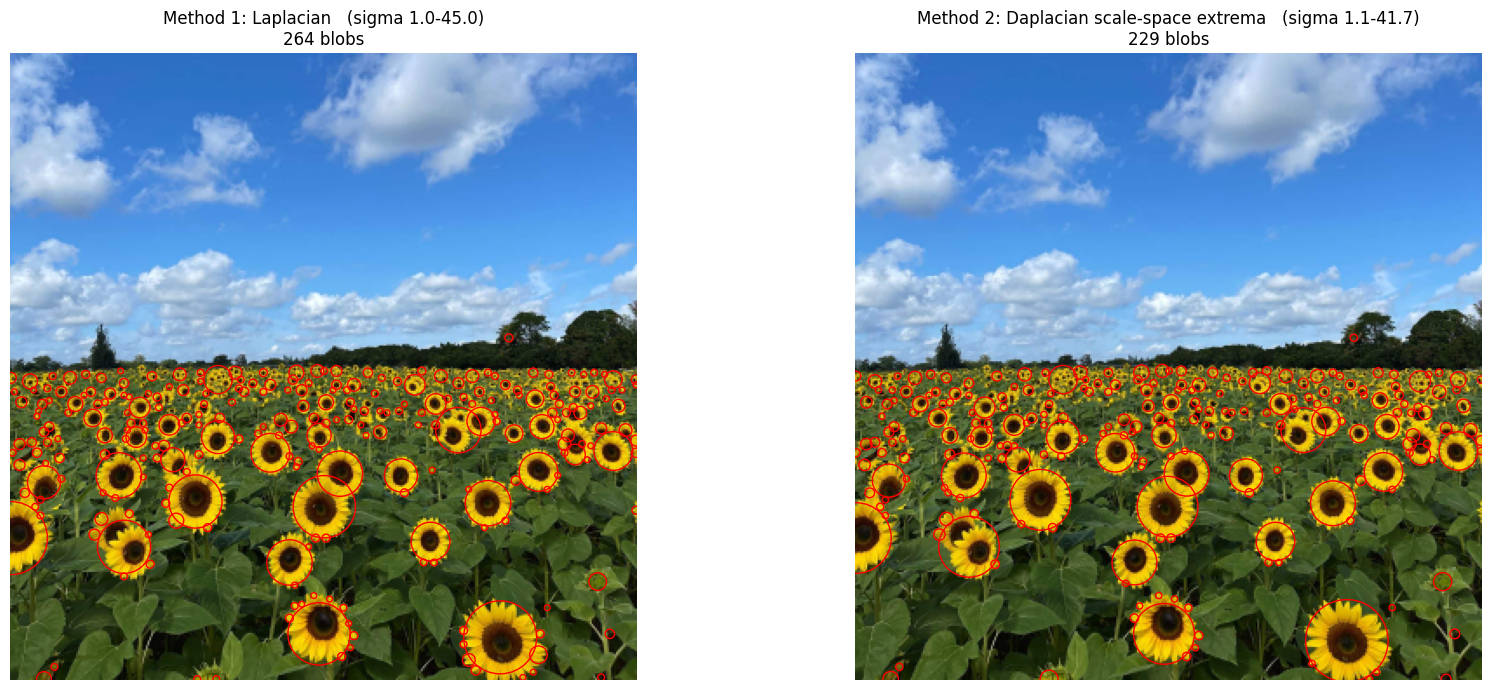

In [ ]:

def main():
    im = cv.imread(IMG_PATH, cv.IMREAD_REDUCED_COLOR_4)
    if im is None:
        raise FileNotFoundError(IMG_PATH)
    im_rgb = cv.cvtColor(im, cv.COLOR_BGR2RGB)
    gray = to_detection_channel(im)
    cv.imwrite('q1_detection_channel.png', (gray * 255).astype(np.uint8))  # for the report

    sigmas = np.geomspace(SIGMA_MIN, SIGMA_MAX, N_SCALES)

    blobs_laplacian = method_laplacian(gray, sigmas)
    report('Method 1: Laplacian of Gaussian', blobs_laplacian, sigmas[0], sigmas[-1])

    k = (SIGMA_MAX / SIGMA_MIN) ** (1.0 / N_SCALES)
    sig_edges = SIGMA_MIN * k ** np.arange(N_SCALES + 1)
    blobs_daplacian, sig_level = method_scale_space(gray, sig_edges)
    report('Method 2: Scale-space extrema (Daplacian)', blobs_daplacian, sig_level[0], sig_level[-1])
    print(f'(Daplacian: Gaussian levels sigma = {sig_edges[0]:.2f} ... {sig_edges[-1]:.2f}, k = {k:.4f})')

    fig, axs = plt.subplots(1, 2, figsize=(18, 7))
    draw(axs[0], im_rgb, blobs_laplacian, f'Method 1: Laplacian   (sigma {sigmas[0]:.1f}-{sigmas[-1]:.1f})')
    draw(axs[1], im_rgb, blobs_daplacian, f'Method 2: Daplacian scale-space extrema   '
                                    f'(sigma {sig_level[0]:.1f}-{sig_level[-1]:.1f})')
    plt.tight_layout()
    plt.savefig('q1_result.png', dpi=150)
    plt.show()


if __name__ == '__main__':
    main()